# Preprocessing

In [1]:
# logic for one sample -> papermill runs this notebook for each sample in the list of patients

Counts come from Pal et al. (2021, EMBO J 40:e107333; GEO GSE161529), distributed as filtered per-sample matrices in genes × cells orientation, so the matrix is transposed on load. All 45 samples share one features.tsv (33,538 genes, CellRanger 3.0.2).

Only filtered matrices are available

Empty droplets are unavailable, so ambient-RNA conatmination cannot be estimated from these matrices.

In [2]:
# this template is intentionally unexecuted 

### Setup

In [3]:
import gzip
import os

In [4]:
os.environ["RPY2_CFFI_MODE"] = "ABI"   # wheel built for R 4.5, we have 4.6

In [5]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns


import rpy2.robjects as ro
from rpy2.robjects import numpy2ri
from rpy2.robjects.conversion import localconverter
from rpy2.robjects.packages import importr

In [6]:
from scipy.sparse import csc_matrix

In [7]:
import session_info

In [8]:
#importr("SingleCellExperiment")
#importr("scDblFinder")
#importr("scry")#Nina needs 2 run this later, 2 save mem

In [9]:
def to_r_sparse(mat):
    """Hand a scipy sparse matrix to R as a dgCMatrix without densifying it.

    The dense route needs 11 GB on the largest sample; this needs ~200 MB and
    gives bit-identical results.
    """
    m = csc_matrix(mat)
    return ro.r["new"]("dgCMatrix",
                       i=ro.IntVector(m.indices.astype(int)),
                       p=ro.IntVector(m.indptr.astype(int)),
                       x=ro.FloatVector(m.data.astype(float)),
                       Dim=ro.IntVector(list(m.shape)))

In [10]:
import scipy.io as sio
from scipy.sparse import csc_matrix

In [11]:
from pathlib import Path

In [12]:
#project  = Path(os.environ.get("CAP_PROJECT","~/Downloads/1105_Project_Nowotny")).expanduser()#4 Helena
project  = Path(os.environ.get("CAP_PROJECT", "/Volumes/TOSHIBA EXT/IdeaProjects/Nowotny")).expanduser()#4 Nina

In [13]:
raw_dir  = Path(os.environ.get("CAP_RAW_DATA","/Volumes/TOSHIBA EXT/IdeaProjects/Nowotny/raw_counts")).expanduser()

In [14]:
head_dir = project / "Adata_Saves" / "ENV1" / "head"
fig_dir  = project / "Figures"
df_dir   = project / "Dataframe_Saves"

In [15]:
for d in [head_dir, fig_dir, df_dir]:
    d.mkdir(parents=True, exist_ok=True)

In [16]:
os.chdir(project)              

In [17]:
sc.settings.figdir = "Figures"  
sc.settings.verbosity = 1
sns.set_theme(style="whitegrid", context="paper")
plt.rcParams["figure.dpi"] = 150
sns.set_theme(style="whitegrid", context="paper", palette="colorblind")
plt.rcParams.update({"font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10, "xtick.labelsize": 10, "ytick.labelsize": 10})

In [18]:
np.random.seed(0)

### Load paths and files

In [19]:
# parameters

patient = None


In [20]:
# Parameters
patient = "GSM4909304_ER-MH0163"


In [21]:
assert patient is not None, "patient must be supplied by papermill"

patient
# example patinetn to run it: patient = "GSM4909281_TN-MH0126"

'GSM4909304_ER-MH0163'

In [22]:
features = pd.read_csv(raw_dir/ "features.tsv", sep="\t", header=None,
                       names=["gene_id", "symbol", "feature_type"])#or features.tsv.gz

In [23]:
#with gzip.open(raw_dir / f"{patient}-matrix.mtx", "rb") as fh:
#    X = sio.mmread(fh).T.tocsr().astype(np.float32)#for Helena, gzipped
X = sio.mmread(raw_dir / f"{patient}-matrix.mtx").T.tocsr().astype(np.float32)#for Nina, not gzipped

In [24]:
#with gzip.open(raw_dir / f"{patient}-barcodes.tsv.gz", "rt") as fh:
#    barcodes = [line.strip() for line in fh]#for Helena, gzipped
with open(raw_dir / f"{patient}-barcodes.tsv", "r") as fh:
    barcodes = [line.strip() for line in fh]#for Nina, not gzipped

In [25]:
adata = ad.AnnData(X=X,
                   obs=pd.DataFrame(index=pd.Index(barcodes, name="barcode")),
                   var=features.set_index("symbol"))

/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1880: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [26]:
adata.var_names_make_unique()

In [27]:
adata.obs["sample"] = patient

In [28]:
adata.obs["condition"] = patient.split("_")[1].split("-")[0]

In [29]:
patient, adata.shape

('GSM4909304_ER-MH0163', (7334, 33538))

In [30]:
adata

AnnData object with n_obs × n_vars = 7334 × 33538
    obs: 'sample', 'condition'
    var: 'gene_id', 'feature_type'

### Quality Control

In [31]:
adata.var["mt"]   = adata.var_names.str.startswith("MT-")

In [32]:
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))

In [33]:
adata.var["hb"]   = adata.var_names.isin(["HBA1", "HBA2", "HBB", "HBD", "HBE1", "HBG1", "HBG2", "HBM", "HBQ1", "HBZ"])

In [34]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"],percent_top=[20], log1p=True, inplace=True)

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [35]:
## cell cycle, scored on a normalised copy, the orignal scored raw counts, which makes the score track library size

Phase scores use the S and G2/M gene sets of Tirosh et al. (2016), computed on a normalised copy so that adata.X retains raw counts. Scoring raw counts makes the score track library size.

In [36]:
s_genes = ["MCM5","PCNA","TYMS","FEN1","MCM2","MCM4","RRM1","UNG","GINS2","MCM6",
           "CDCA7","DTL","PRIM1","UHRF1","HELLS","RFC2","RPA2","NASP","RAD51AP1",
           "GMNN","WDR76","SLBP","CCNE2","UBR7","POLD3","MSH2","ATAD2","RAD51",
           "RRM2","CDC45","CDC6","EXO1","TIPIN","DSCC1","BLM","CASP8AP2","USP1",
           "CLSPN","POLA1","CHAF1B","BRIP1","E2F8"]

In [37]:

g2m_genes = ["HMGB2","CDK1","NUSAP1","UBE2C","BIRC5","TPX2","TOP2A","NDC80","CKS2",
             "NUF2","CKS1B","MKI67","TMPO","CENPF","TACC3","SMC4","CCNB2","CKAP2L",
             "CKAP2","AURKB","BUB1","KIF11","ANP32E","TUBB4B","GTSE1","KIF20B",
             "HJURP","CDCA3","CDC20","TTK","CDC25C","KIF2C","RANGAP1","NCAPD2",
             "DLGAP5","CDCA2","CDCA8","ECT2","KIF23","HMMR","AURKA","PSRC1","ANLN",
             "LBR","CKAP5","CENPE","CTCF","NEK2","G2E3","GAS2L3","CBX5","CENPA"]

In [38]:
tmp = adata.copy()

In [39]:
sc.pp.normalize_total(tmp, target_sum=1e4)
sc.pp.log1p(tmp)

In [40]:
sc.tl.score_genes_cell_cycle(tmp, s_genes=s_genes, g2m_genes=g2m_genes)

In [41]:
for col in ["S_score", "G2M_score", "phase"]:
    adata.obs[col] = tmp.obs[col].values
del tmp

### QC plot before filtering

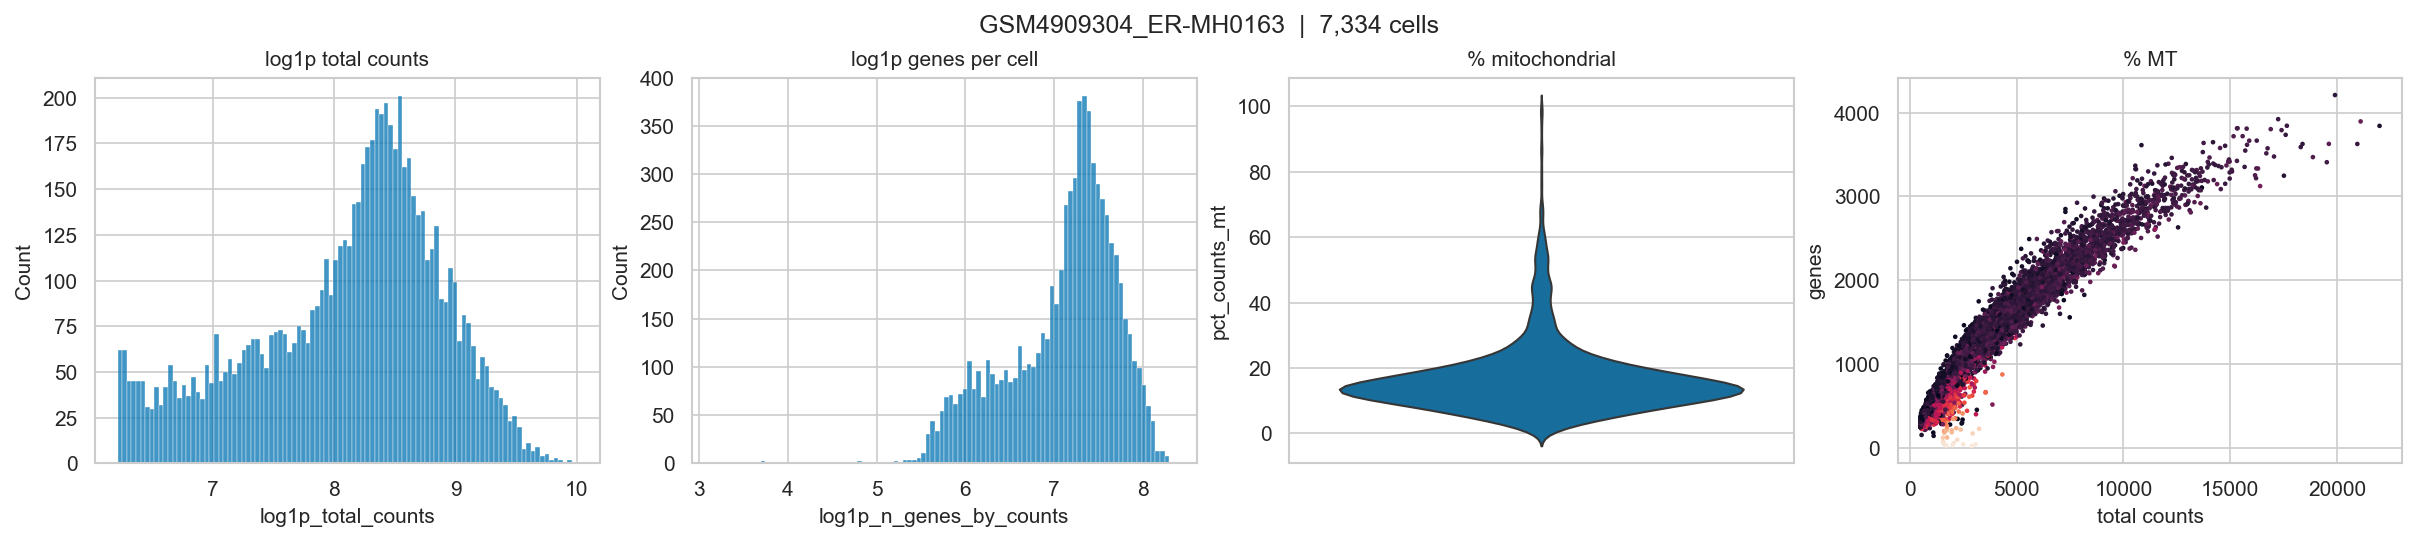

In [42]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), constrained_layout=True)
fig.suptitle(f"{patient}  |  {adata.n_obs:,} cells")
sns.histplot(adata.obs["log1p_total_counts"], bins=100, ax=axes[0])
axes[0].set_title("log1p total counts")
sns.histplot(adata.obs["log1p_n_genes_by_counts"], bins=100, ax=axes[1])
axes[1].set_title("log1p genes per cell")
sns.violinplot(y=adata.obs["pct_counts_mt"], ax=axes[2], inner=None)
axes[2].set_title("% mitochondrial")
axes[3].scatter(adata.obs["total_counts"], adata.obs["n_genes_by_counts"],
                c=adata.obs["pct_counts_mt"], s=2)
axes[3].set(xlabel="total counts", ylabel="genes", title="% MT")
plt.savefig(fig_dir / f"{patient}_qc_before.png", bbox_inches="tight")

plt.show()

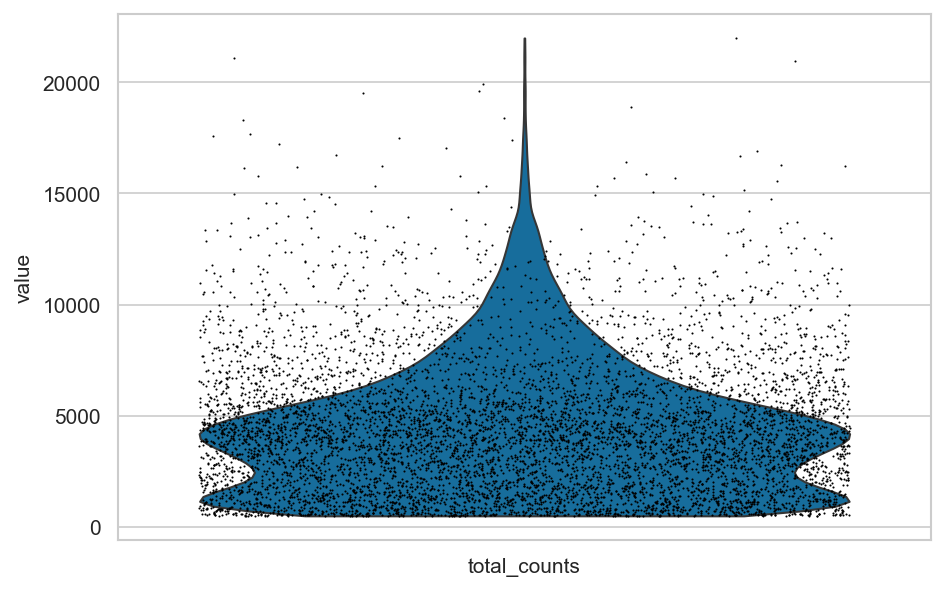

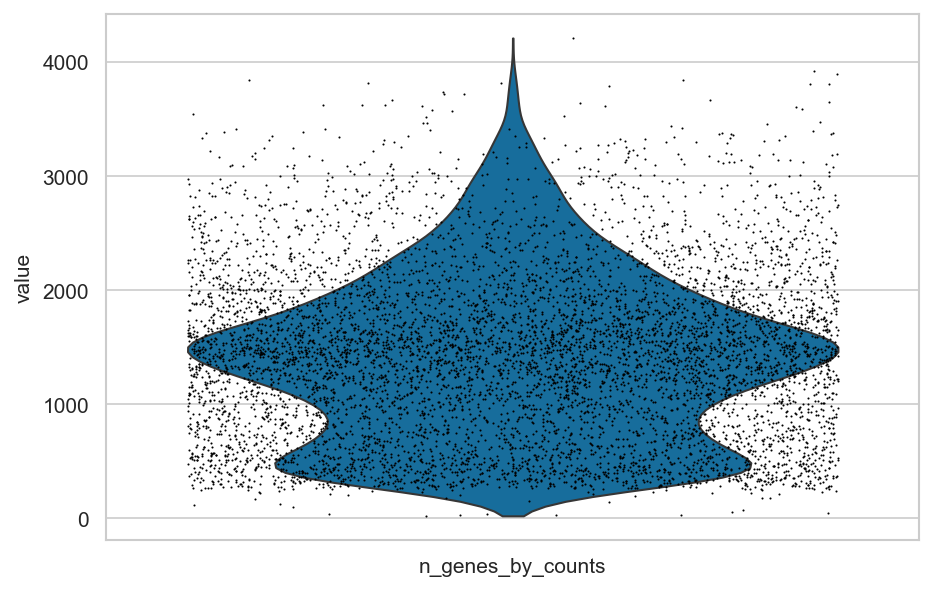

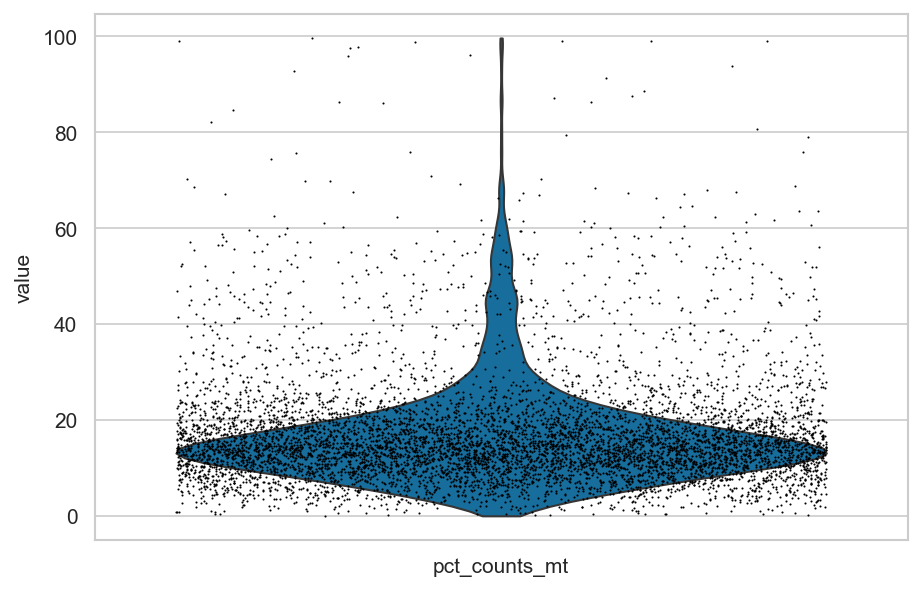

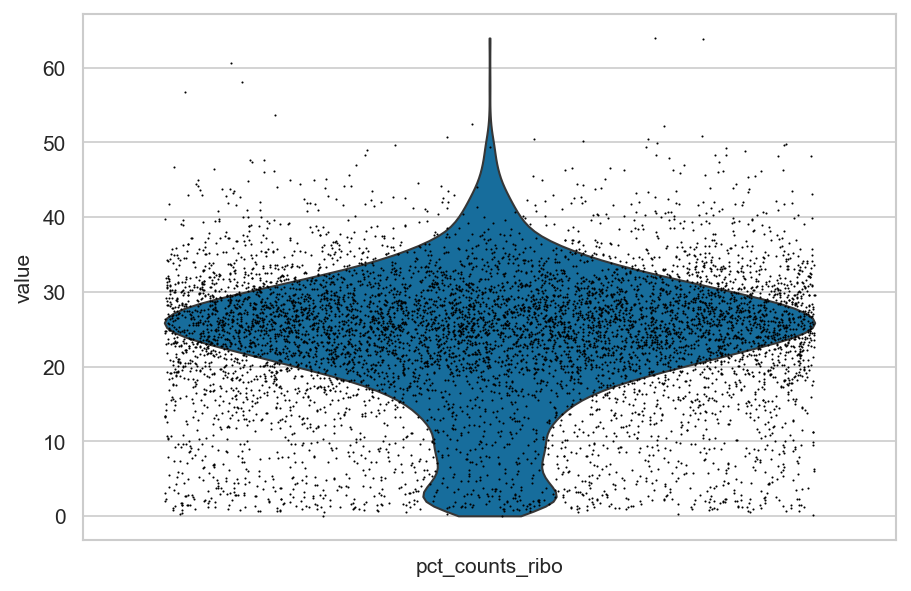

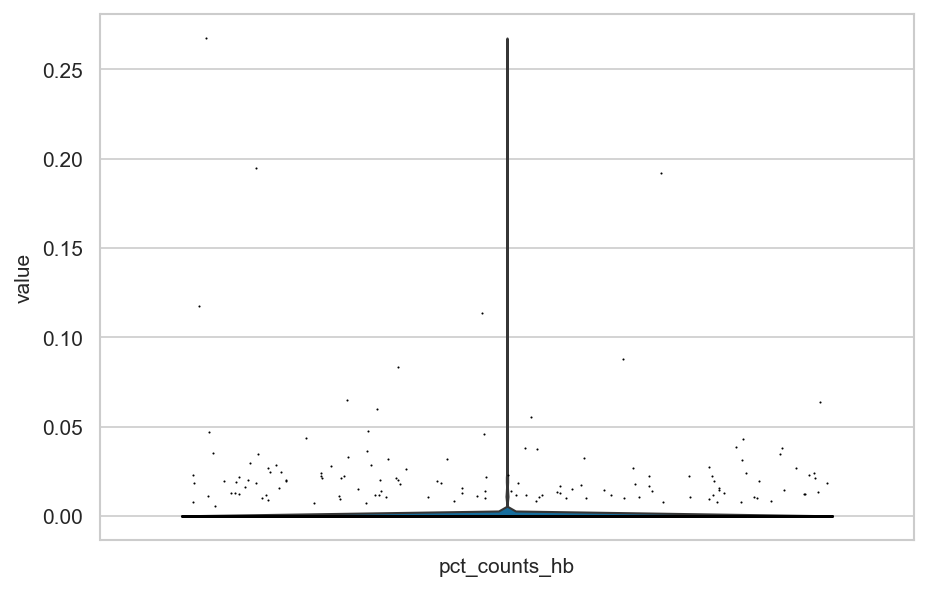

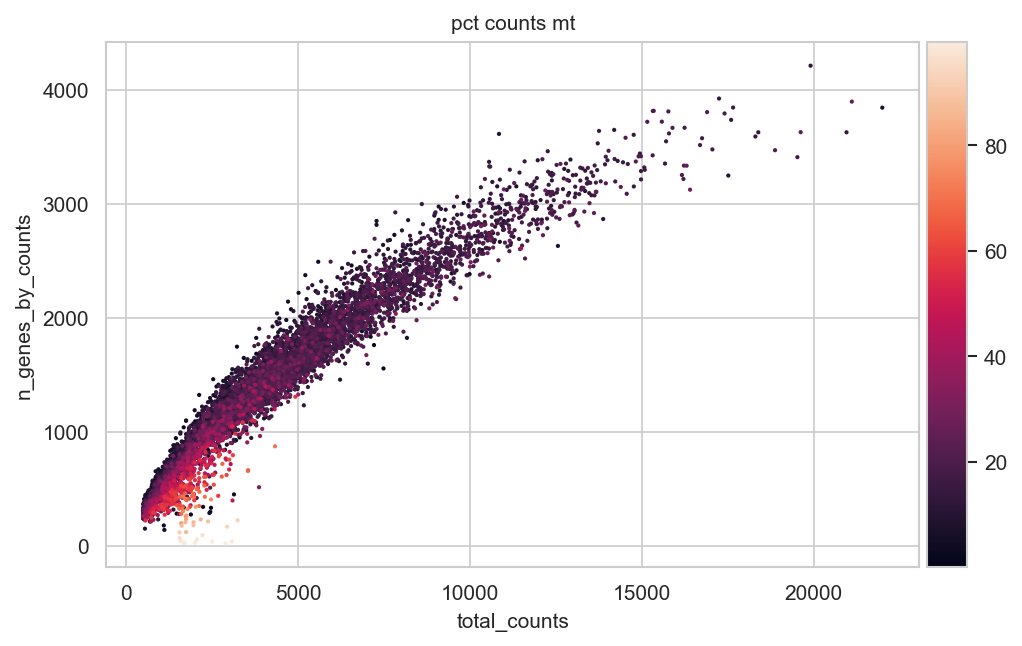

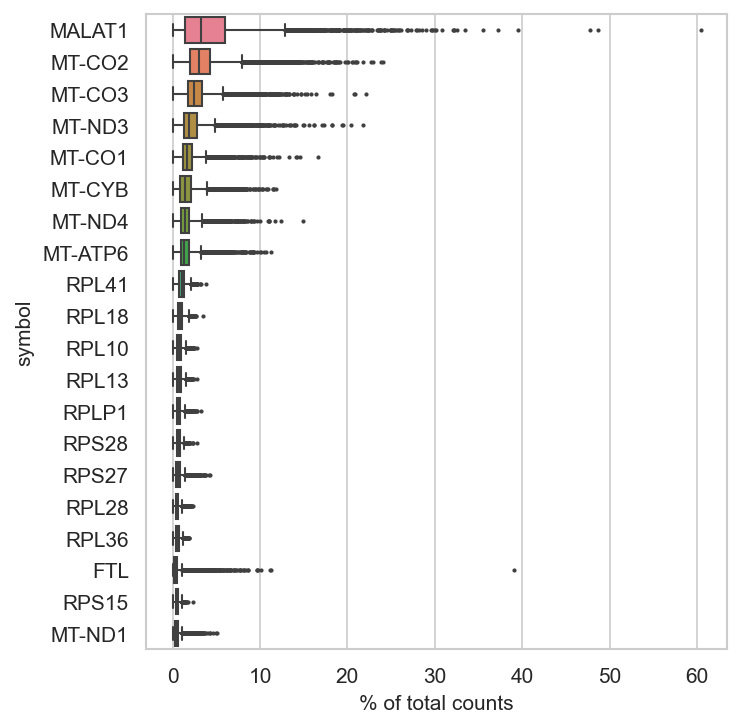

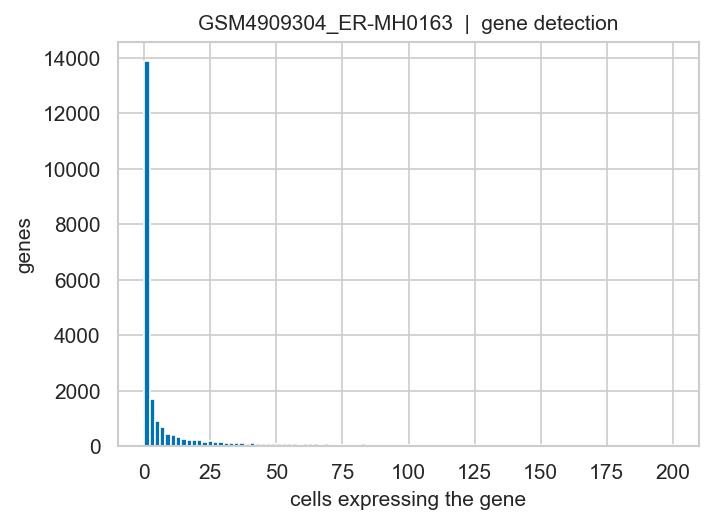

In [43]:
# how deep is each cell sequenced
sc.pl.violin(adata, "total_counts", jitter=0.4, save=f"_{patient}_counts.png")
# how many genes does each cell detect
sc.pl.violin(adata, "n_genes_by_counts", jitter=0.4, save=f"_{patient}_genes.png")
# dying cells sit high here
sc.pl.violin(adata, "pct_counts_mt", jitter=0.4, save=f"_{patient}_mito.png")
sc.pl.violin(adata, "pct_counts_ribo", jitter=0.4, save=f"_{patient}_ribo.png")
# red blood cell contamination
sc.pl.violin(adata, "pct_counts_hb", jitter=0.4, save=f"_{patient}_hb.png")
# the classic QC plot: empty droplets bottom left, doublets top right, dying cells the high-mito streak
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt",
              save=f"_{patient}_counts_vs_genes.png")
# if one gene takes a large share of all counts, something is wrong
sc.pl.highest_expr_genes(adata, n_top=20, save=f"_{patient}_top_genes.png")
# most genes are seen in almost no cells - this is what the HVG step is up against
n_cells = np.asarray((adata.X > 0).sum(axis=0)).ravel()
plt.figure(figsize=(5, 3.5))
plt.hist(n_cells, bins=100, range=(0, 200))
plt.xlabel("cells expressing the gene")
plt.ylabel("genes")
plt.title(f"{patient}  |  gene detection")
plt.savefig(fig_dir / f"{patient}_gene_detection.png", bbox_inches="tight")

plt.show()

In [44]:
# where the four target genes sit, before any filtering touches them
for g in ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]:
    if g in adata.var_names:
        x = np.asarray(adata[:, g].X.todense()).ravel()
        print(f"{g:6s} detected in {(x > 0).sum():5d} / {adata.n_obs} cells "
              f"({100 * (x > 0).mean():5.2f}%)   max {int(x.max())} UMI")
    else:
        print(f"{g:6s} not in this sample")

ROR1   detected in     4 / 7334 cells ( 0.05%)   max 1 UMI
ROR2   detected in    25 / 7334 cells ( 0.34%)   max 3 UMI
EGFR   detected in     2 / 7334 cells ( 0.03%)   max 1 UMI
ERBB2  detected in  1110 / 7334 cells (15.13%)   max 4 UMI
EPCAM  detected in  1903 / 7334 cells (25.95%)   max 5 UMI


## Filter cells 


In [45]:
importr("SingleCellExperiment")
importr("scDblFinder")
importr("scry")

rpy2.robjects.packages.Package as a <module 'scry'>

In [46]:
# One mitochondrial threshold for every sample. FIltering normals at 20% and tumours at 40% makes every normal-vs-tumour comparison partly a comparison of two filters miQC: per-cell probability of being compromised, from the joint distribution of MT% and gene count. Dying cells have high MT AND low complexity; metabolically active tumour cells have high MT and normal complexity, and are kept.

In [47]:
# no gene filter here -> it would delete ROR1

In [48]:
with localconverter(ro.default_converter + numpy2ri.converter):
    ro.globalenv["mito"]  = adata.obs["pct_counts_mt"].to_numpy()
    ro.globalenv["ngene"] = adata.obs["n_genes_by_counts"].to_numpy().astype(float)

In [49]:

ro.r("""
    suppressMessages({library(miQC); library(SingleCellExperiment)})
    sce <- SingleCellExperiment(assays = list(counts = matrix(0, nrow = 1, ncol = length(mito))))
    colnames(sce) <- as.character(seq_along(mito))
    sce$subsets_mito_percent <- mito
    sce$detected <- ngene
    set.seed(0)
    model <- tryCatch(suppressWarnings(mixtureModel(sce)), error = function(e) NULL)
    miqc_ok <- !is.null(model) && length(model@components) >= 2
    kept <- if (miqc_ok) as.integer(colnames(filterCells(sce, model, verbose = FALSE))) else integer(0)
""")

In [50]:
# On very clean samples the mixture collapses to one component and miQC cannot separate a compromised population. Fall back to a fixed threshold there, and record which samples fell back.
miqc_ok = bool(ro.globalenv["miqc_ok"][0])

In [51]:
if miqc_ok:
    miqc_keep = np.zeros(adata.n_obs, dtype=bool)
    miqc_keep[np.asarray(ro.globalenv["kept"]).astype(int) - 1] = True
else:
    print("miQC could not resolve two components - falling back to a fixed 20% threshold")
    miqc_keep = (adata.obs["pct_counts_mt"] <= 20).to_numpy()

A floor of 10% prevents over-filtering of clean samples, where the mixture otherwise splits the upper tail of a healthy distribution.

In [52]:
# On a clean sample miQC splits the upper tail of a healthy distribution and cuts at ~3.5% MT. Never call a cell compromised below this.
mt_floor = 10

In [53]:
miqc_keep |= (adata.obs["pct_counts_mt"] < mt_floor).to_numpy()

In [54]:
mt_filter_path = "miqc" if miqc_ok else "fixed_20pct"

In [55]:
keep = (
    (adata.obs["total_counts"] >= 500).to_numpy()
    & (adata.obs["total_counts"] <= 40_000).to_numpy()
    & (adata.obs["pct_counts_hb"] <= 3).to_numpy()
    & miqc_keep
)

In [56]:
adata.n_obs, keep.sum(), adata.obs['pct_counts_mt'][keep].max()

(7334, np.int64(6462), np.float32(31.258106))

In [57]:
adata = adata[keep].copy()

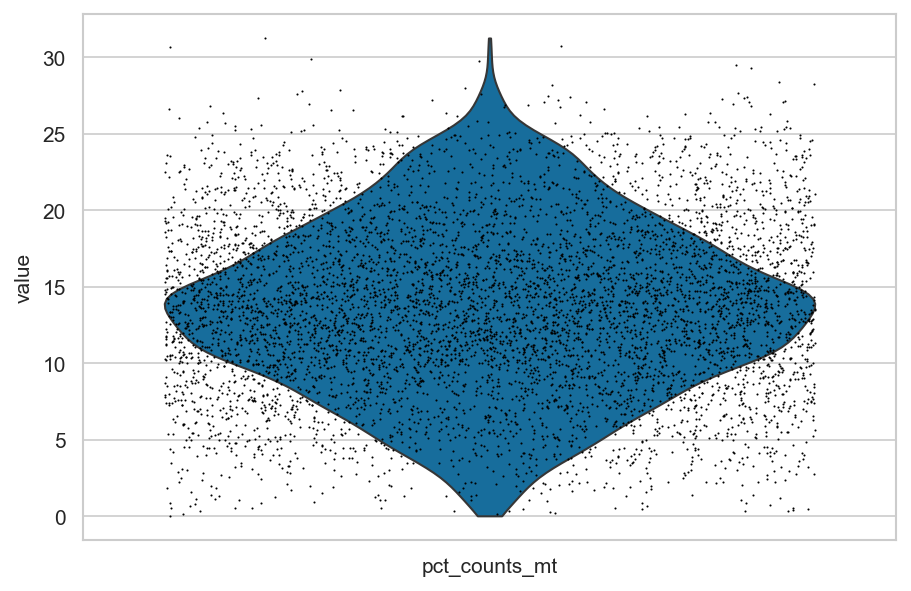

In [58]:
sc.pl.violin(adata, "pct_counts_mt", jitter=0.4, save=f"_{patient}_mito_after.png")

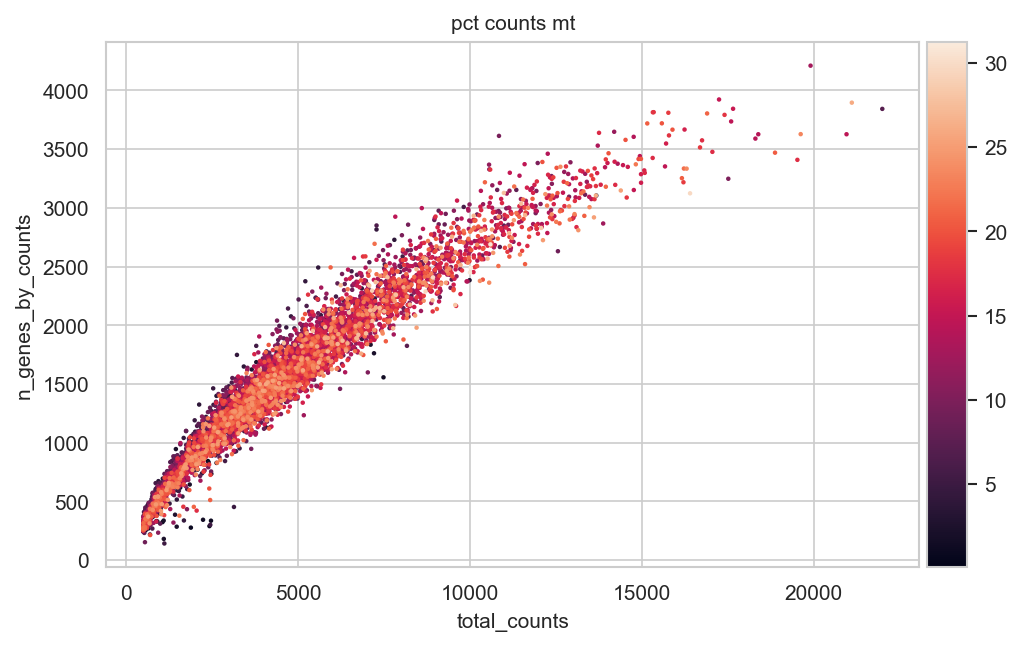

In [59]:
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt",
              save=f"_{patient}_counts_vs_genes_after.png")

In [60]:
# No sc.pp.filter_genes

# Doublet removal with scDblFinder 

In [61]:
ro.globalenv["counts"] = to_r_sparse(adata.X.T)

In [62]:
ro.r("""
    set.seed(0)
    sce <- scDblFinder(SingleCellExperiment(list(counts = counts)))
    doublet_class <- as.character(sce$scDblFinder.class)
    doublet_score <- sce$scDblFinder.score
""")

R callback write-console: Creating ~5170 artificial doublets...
  


R callback write-console: Dimensional reduction
  


R callback write-console: Evaluating kNN...
  


R callback write-console: Training model...
  


R callback write-console: iter=0, 503 cells excluded from training.
  


...

R callback write-console: In .local(x, ...) :  


R callback write-console:  'normalizeCounts' is deprecated.
Use 'scrapper::normalizeCounts' instead.
See help("Deprecated")
  


R callback write-console: 2:   


R callback write-console: In .local(x, ...) :  


R callback write-console:  'librarySizeFactors' is deprecated.
Use 'scrapper::centerSizeFactors' instead.
See help("Deprecated")
  


In [63]:
adata.obs["doublet_score"] = np.asarray(ro.globalenv["doublet_score"])

In [64]:
adata.obs["doublet_class"] = np.asarray(ro.globalenv["doublet_class"]).astype(str)

In [65]:
assert set(adata.obs["doublet_class"]) <= {"singlet", "doublet"}, \
    set(adata.obs["doublet_class"])

In [66]:
adata.obs["doublet_class"].value_counts().to_string()

'doublet_class\nsinglet    5890\ndoublet     572'

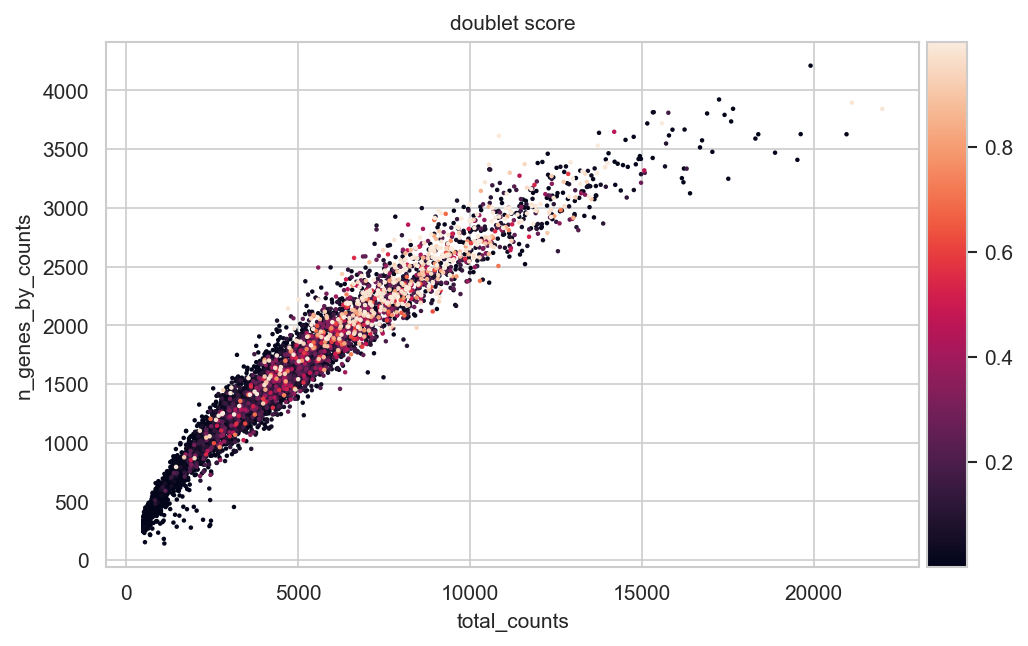

In [67]:
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="doublet_score",
              save=f"_{patient}_doublets.png")

In [68]:
# are doublets enriched for the co-expression we care about?
def pos(g):
    return np.asarray(adata[:, g].X.todense()).ravel() > 0 if g in adata.var_names \
           else np.zeros(adata.n_obs, bool)

In [69]:
dbl = (adata.obs["doublet_class"] == "doublet").to_numpy()

In [70]:
ror1_egfr_dp = pos("ROR1") & pos("EGFR")

In [71]:
epcam_erbb2_dp = pos("EPCAM") & pos("ERBB2")

In [72]:
for name, dp_mask in [("ROR1+EGFR", ror1_egfr_dp), ("EPCAM+ERBB2", epcam_erbb2_dp)]:
    if dp_mask.sum() == 0:
        print(f"{name}: none in this sample")
        continue
    print(f"{name}: {dp_mask.sum()} double positive, "
          f"{100 * dbl[dp_mask].mean():.0f}% of them are doublets "
          f"(background {100 * dbl.mean():.1f}%)")

ROR1+EGFR: none in this sample
EPCAM+ERBB2: 371 double positive, 13% of them are doublets (background 8.9%)


In [73]:
n_before_doublets = adata.n_obs

In [74]:
n_doublets = int((adata.obs["doublet_class"] == "doublet").sum())

In [75]:
adata = adata[adata.obs["doublet_class"] == "singlet"].copy()

In [76]:
adata.n_obs, n_doublets, 100 * n_doublets / n_before_doublets

(5890, 572, 8.851748684617766)

In [77]:
# normalise, keep raw counts 

In [78]:
adata.layers["counts"] = adata.X.copy()

In [79]:
sc.pp.normalize_total(adata, target_sum=1e4)

In [80]:
sc.pp.log1p(adata)

In [81]:
adata.layers["log1p"] = adata.X.copy()

# feature selection with scry

In [82]:
ro.globalenv["counts"] = to_r_sparse(adata.layers["counts"].T)

In [83]:
ro.r("""
    sce <- SingleCellExperiment(list(counts = counts))
    sce <- devianceFeatureSelection(sce)
    deviance <- rowData(sce)$binomial_deviance
""")

In [84]:
adata.var["deviance"] = np.asarray(ro.globalenv["deviance"])

In [85]:
exclude = adata.var[["mt", "ribo", "hb"]].any(axis=1).to_numpy()

In [86]:
exclude |= adata.var_names.isin(s_genes + g2m_genes)

In [87]:
order = np.argsort(adata.var["deviance"].to_numpy())[::-1]

In [88]:
top = order[~exclude[order]][:2000]
adata.var["highly_variable"] = False
adata.var.iloc[top, adata.var.columns.get_loc("highly_variable")] = True

In [89]:
adata.var["highly_variable"].sum()

np.int64(2000)

In [90]:
mean_expr = np.asarray(adata.layers["counts"].mean(axis=0)).ravel()

In [91]:
hv = adata.var["highly_variable"].to_numpy()

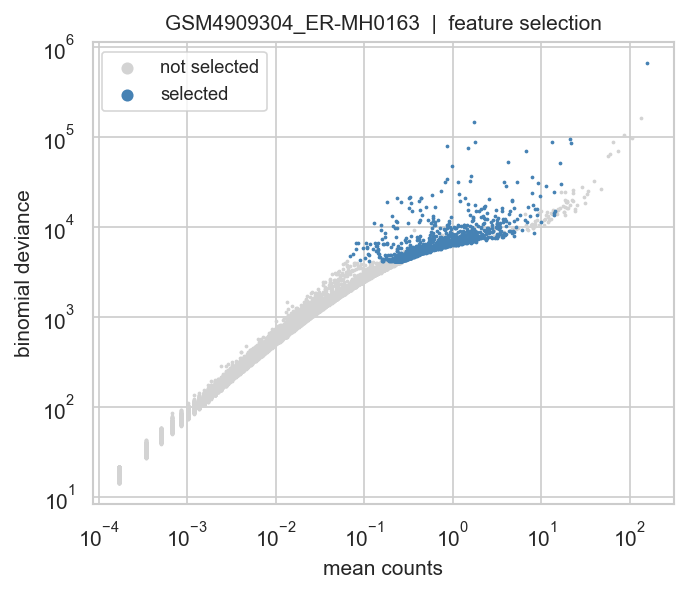

In [92]:
plt.figure(figsize=(5, 4))
plt.scatter(mean_expr[~hv], adata.var["deviance"][~hv], s=1, c="lightgrey", label="not selected")
plt.scatter(mean_expr[hv],  adata.var["deviance"][hv],  s=1, c="steelblue", label="selected")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("mean counts"); plt.ylabel("binomial deviance")
plt.title(f"{patient}  |  feature selection")
plt.legend(markerscale=5)
plt.savefig(fig_dir / f"{patient}_deviance.png", bbox_inches="tight")
plt.show()

# PCA and depth check

In [93]:
sc.pp.pca(adata, n_comps=50, mask_var="highly_variable")

In [94]:
r = np.corrcoef(adata.obsm["X_pca"][:, 0], adata.obs["total_counts"])[0, 1]

In [95]:
r

np.float64(0.7144540477702129)

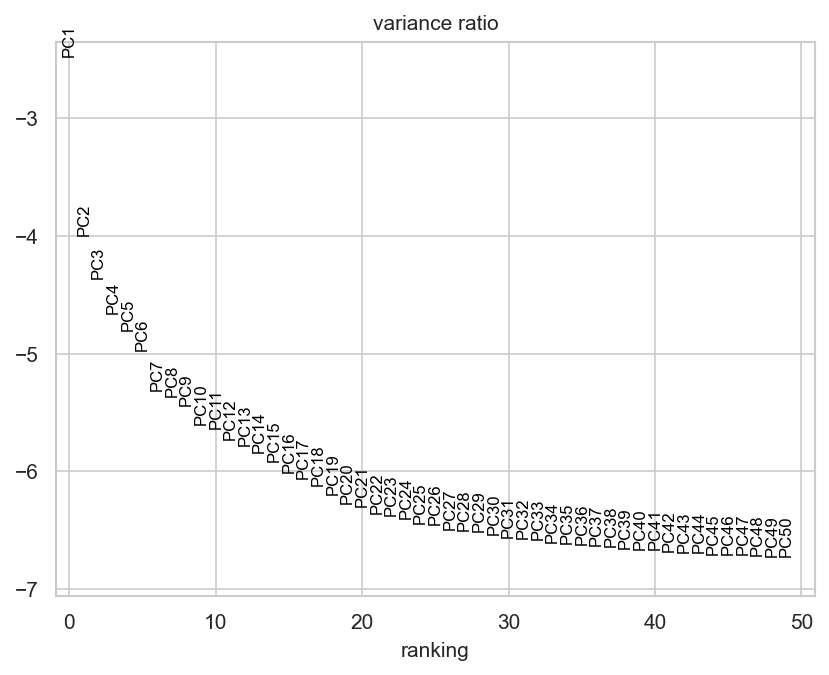

In [96]:
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True, save=f"_{patient}_elbow.png")

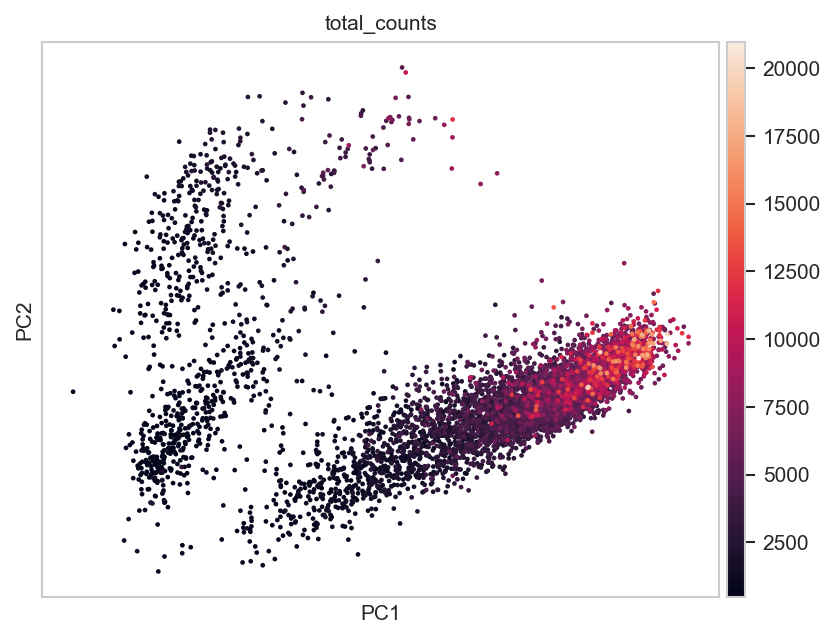

In [97]:
# if this looks like a gradient, library size is still driving the structure
sc.pl.pca(adata, color="total_counts", save=f"_{patient}_pca_depth.png")

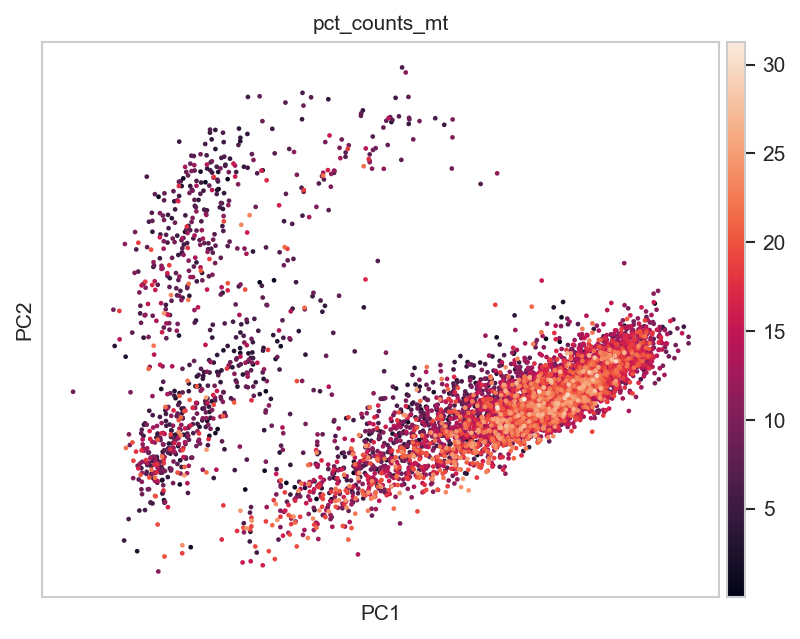

In [98]:
sc.pl.pca(adata, color="pct_counts_mt", save=f"_{patient}_pca_mito.png")

# save object

In [99]:
adata.X = adata.layers["counts"].copy()

In [100]:
adata.write_h5ad(head_dir / f"{patient}.h5ad")

In [101]:
adata

AnnData object with n_obs × n_vars = 5890 × 33538
    obs: 'sample', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'S_score', 'G2M_score', 'phase', 'doublet_score', 'doublet_class'
    var: 'gene_id', 'feature_type', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'deviance', 'highly_variable'
    uns: 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts', 'log1p'

In [102]:
# One row per sample. papermill.ipynb concatenates all 45 into the supplementary QC table.
print("=" * 60)
print("ABOUT TO WRITE QC")
print("patient:", patient)
print("df_dir:", df_dir)
print("target:", df_dir / f"qc_{patient}.csv")
print("=" * 60)

pd.DataFrame([{
    "sample":          patient,
    "condition":       str(adata.obs["condition"].iloc[0]),
    "n_cells_final":   adata.n_obs,
    "n_genes":         adata.n_vars,
    "miqc_mt_cutoff":  round(float(adata.obs["pct_counts_mt"].max()), 1),
    "pct_doublets":    round(100 * n_doublets / n_before_doublets, 1),
    "pc1_depth_corr":  round(float(r), 3),
    "median_counts":   int(adata.obs["total_counts"].median()),
    "median_genes":    int(adata.obs["n_genes_by_counts"].median()),
    "ror1_egfr_dp": int(ror1_egfr_dp.sum()),
    "ror1_egfr_dp_doublet_pct": round(100 * dbl[ror1_egfr_dp].mean(), 1) if ror1_egfr_dp.any() else np.nan,
    "epcam_erbb2_dp": int(epcam_erbb2_dp.sum()),
    "epcam_erbb2_dp_doublet_pct": round(100 * dbl[epcam_erbb2_dp].mean(), 1) if epcam_erbb2_dp.any() else np.nan,
    "miqc_converged": miqc_ok,
    "mt_filter_path": mt_filter_path,
    "mt_floor": mt_floor,
}]).to_csv(df_dir / f"qc_{patient}.csv", index=False)

ABOUT TO WRITE QC
patient: GSM4909304_ER-MH0163
df_dir: /Volumes/TOSHIBA EXT/IdeaProjects/Nowotny/Dataframe_Saves
target: /Volumes/TOSHIBA EXT/IdeaProjects/Nowotny/Dataframe_Saves/qc_GSM4909304_ER-MH0163.csv


In [103]:
f"qc_{patient}.csv"

'qc_GSM4909304_ER-MH0163.csv'

In [104]:
# run papermill on this notebook for each patient in the list of patients to generate a separate h5ad file for each patient

In [105]:
session_info.show(excludes=["scry"])

/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/session_info/main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  mod_version = _find_version(mod.__version__)
/Users/gernotstuhler/miniforge3_arm64/envs/scFates/lib/python3.11/site-packages/session_info/main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  mod_version = _find_version(mod.__version__)
